### Load libraries

In [1]:
# Basic libraries
import os, sys
from datetime import date
import warnings
warnings.simplefilter(action='ignore', category=FutureWarning)
import pandas as pd 
pd.set_option('display.max_rows', 500)
import numpy as np 
import scanpy as sc 
import seaborn as sns
import matplotlib.pyplot as plt
import warnings

# DGE analysis
import pydeseq2
from pydeseq2.dds import DeseqDataSet
from pydeseq2.ds import DeseqStats
import decoupler 

# GO analysis
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap
import seaborn as sns
import gseapy as gp
from gseapy.plot import gseaplot

In [2]:
env_path = "../.env"
# call paths from .env
if os.path.exists(env_path):
    with open(env_path) as f:
        os.environ.update(
            line.strip().split("=", 1) for line in f
            if line.strip() and not line.startswith("#")
        )
        
plots_dir = os.getenv("PLOTS_DIR")
processed_adata_dir = os.getenv("PROCESSED_ANNDATA_DIR")
src_dir = os.getenv("SRC_DIR")
res_dir = os.getenv("RESULTS_DIR")
ontology_dir  = os.getenv("ONTOLOGY_DIR")

### Load the data

In [3]:
# load pseudobulked adata
pdata = sc.read_h5ad(processed_adata_dir + "pdata_pseudobulked_RG_subclusters.h5ad")

### DGE analysis

In [4]:
# Subset to clusters of interest
rg2_hs_ncx_mm_dg = pdata[(pdata.obs['leiden_subclustered_G1 RG'].isin(['RG 2'])) & (pdata.obs['species'].isin(['human_ncx', 'mouse_dg']))].copy()

In [5]:
# Prepare the DeSeq2 format
rg2_hs_ncx_mm_dg.layers['counts'] = rg2_hs_ncx_mm_dg.X.copy()

dds = DeseqDataSet(
    adata = rg2_hs_ncx_mm_dg,    
    design_factors= ['RG_subclusters'],
    ref_level=['RG_subclusters', 'hs_ncx'],
    refit_cooks=True)

/tmp/ipykernel_1488347/2034121412.py:4: UserWarning: Same factor names in the design contain underscores ('_'). They will
                be converted to hyphens ('-').
  dds = DeseqDataSet(
/usr/local/lib/python3.10/dist-packages/pydeseq2/dds.py:270: UserWarning: Some factor levels in the design contain underscores ('_').
                    They will be converted to hyphens ('-').
  self.obsm["design_matrix"] = build_design_matrix(


In [6]:
# Perform deseq2
dds.deseq2() 

Fitting size factors...
... done in 0.01 seconds.

Fitting dispersions...
... done in 3.48 seconds.

Fitting dispersion trend curve...
... done in 0.30 seconds.

Fitting MAP dispersions...
... done in 3.67 seconds.

Fitting LFCs...
... done in 2.88 seconds.

Calculating cook's distance...
... done in 0.02 seconds.

Replacing 74 outlier genes.

Fitting dispersions...
... done in 0.05 seconds.

Fitting MAP dispersions...
... done in 0.04 seconds.

Fitting LFCs...
... done in 0.05 seconds.



In [7]:
# Output results
stat_res = DeseqStats(dds, contrast=['RG-subclusters', 'hs-ncx', 'mm-dg'])
stat_res.summary()

Running Wald tests...


Log2 fold change & Wald test p-value: RG-subclusters hs-ncx vs mm-dg
          baseMean  log2FoldChange     lfcSE      stat        pvalue      padj
A1BG      0.000000             NaN       NaN       NaN           NaN       NaN
A2M       2.644120       -3.998086  0.887072 -4.507061  6.573180e-06  0.000039
A3GALT2   0.000000             NaN       NaN       NaN           NaN       NaN
A4GALT    0.000000             NaN       NaN       NaN           NaN       NaN
AAAS     16.274303        2.262121  0.459705  4.920812  8.618605e-07  0.000006
...            ...             ...       ...       ...           ...       ...
ZXDC     10.411214        0.219712  0.467112  0.470362  6.380966e-01  0.716137
ZYG11B   34.134721        0.597308  0.285950  2.088852  3.672109e-02  0.069933
ZYX      18.534974        1.256257  0.370168  3.393748  6.894308e-04  0.002336
ZZEF1     9.975777       -1.191352  0.459423 -2.593148  9.510180e-03  0.022237
ZZZ3     33.213830        0.521448  0.424953  1.227073  2.1979

... done in 1.09 seconds.



In [8]:
# Output the dataframe
results_df = stat_res.results_df
# Background genes
background = results_df.dropna(subset=['padj'])
print(len(background))

12636


In [9]:
# Output the dataframe
results_df = stat_res.results_df
results_df = results_df[results_df['baseMean'] > 1]
# Reindex the dataframe
results_df_copy = results_df.copy()
results_df_copy.reset_index(inplace=True)
results_df_copy.rename(columns ={'index':'gene_name'}, inplace = True)

In [10]:
# Convert to -log10padj
results_df['log_10_padj'] = -np.log10(results_df['padj'])
# Cap the -log10padj
cap = 10
results_df['log_10_padj_capped'] = np.where(results_df['log_10_padj']>cap, cap, results_df['log_10_padj'])

/tmp/ipykernel_1488347/4004247051.py:2: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  results_df['log_10_padj'] = -np.log10(results_df['padj'])
/tmp/ipykernel_1488347/4004247051.py:5: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  results_df['log_10_padj_capped'] = np.where(results_df['log_10_padj']>cap, cap, results_df['log_10_padj'])


In [11]:
# Filter the p adjusted 
DEGs = results_df[results_df['padj'] < 0.05]
# Filtr the log2FC
degs_human_up = DEGs[DEGs['log2FoldChange'] > 1]
degs_human_down = DEGs[DEGs['log2FoldChange'] < -1]
# Print the number of up and down-regulated genes
print(len(degs_human_up))
print(len(degs_human_down))

3341
2276


In [12]:
# save DEGs and background
degs_human_up.to_csv(res_dir + 'degs/hs_ncx_rg2_vs_mm_dg_rg_2/DEGs_up_hs_ncx_rg2_v_mm_dg_rg_2_FULL.csv')
degs_human_down.to_csv(res_dir + 'degs/hs_ncx_rg2_vs_mm_dg_rg_2/DEGs_down_hs_ncx_rg2_v_mm_dg_rg_2_FULL.csv')
background.to_csv(res_dir + 'degs/hs_ncx_rg2_vs_mm_dg_rg_2/DEGs_background_hs_ncx_rg2_v_mm_dg_rg_2_FULL.csv')
print(len(background))

12636


In [13]:
# gene lists
degs_human_up_list = degs_human_up.reset_index()['index'].tolist()
degs_human_down_list = degs_human_down.reset_index()['index'].tolist()

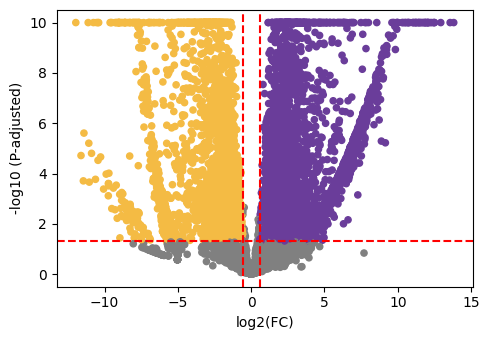

In [14]:
script_path = src_dir + 'Volcano_plot.py'
%run -i $script_path
# Plot the volcano plot
volcano_plot(df = results_df, df_up=degs_human_up, df_down=degs_human_down)
plt.grid(False)
plt.tight_layout()
plt.savefig(plots_dir + 'degs/hs_ncx_rg2_vs_mm_dg_rg_2/Volcano_plot_hs_ncx_rg2_vs_mm_dg_rg_2_FULL.png', dpi = 300, bbox_inches = 'tight')
plt.savefig(plots_dir + 'degs/hs_ncx_rg2_vs_mm_dg_rg_2/Volcano_plot_hs_ncx_rg2_vs_mm_dg_rg_2_FULL.svg', dpi = 300, bbox_inches = 'tight')
plt.show()

#### GO

In [15]:
# Intersect individual background lists 
background_list = background.reset_index()['index'].tolist()
print(len(background_list))

12636


In [16]:
# up-regulated genes
degs_intersected_up = degs_human_up.reset_index()['index'].tolist()
print(len(degs_intersected_up))

3341


In [17]:
# intersect down-regulated genes
degs_intersected_down = degs_human_down.reset_index()['index'].tolist()
print(len(degs_intersected_down))

2276


In [18]:
# Load the ontology lists
ontology_list = ontology_dir + 'msigdb/c5.go.bp.v2023.2.Hs.symbols.gmt'

In [19]:
# Perform GO analysis
# Intersected Up-regulated in hs-ncx-rg-2
hsNcx_vs_mmDG_up = gp.enrichr(gene_list= degs_intersected_up, 
                                  gene_sets= ontology_list, 
                                  organism='Human', 
                                  cutoff=0.5, 
                                  background = background_list,
                                  no_plot= True)

hsNcx_vs_mmDG_up_df = pd.DataFrame(hsNcx_vs_mmDG_up.results)

# Down-regulated in human Ncx bRG 1 vs mouse DG bRG 1
hsNcx_vs_mmDG_down = gp.enrichr(gene_list= degs_intersected_down, 
                                    gene_sets= ontology_list, 
                                    organism='Human', 
                                    cutoff=0.5, 
                                    background = background_list,
                                    no_plot= True)

hsNcx_vs_mmDG_down_df = pd.DataFrame(hsNcx_vs_mmDG_down.results)

In [20]:
# Save the files
# up-regulated GO terms
hsNcx_vs_mmDG_up_df.to_csv(res_dir + 'GO/hs_ncx_rg2_vs_mm_dg_rg_2/GO_hs_ncx_rg2_vs_mm_dg_rg_2_UP_enrichment_FULL.csv')
# down-regulated GO terms
hsNcx_vs_mmDG_down_df.to_csv(res_dir + 'GO/hs_ncx_rg2_vs_mm_dg_rg_2/GO_hs_ncx_rg2_vs_mm_dg_rg_2_DOWN_enrichment_FULL.csv')

In [21]:
# Define the 'Gene ontology type' 
hsNcx_vs_mmDG_up_df['Ontology_type'] = hsNcx_vs_mmDG_up_df.Gene_set.str[:8]
hsNcx_vs_mmDG_down_df['Ontology_type'] = hsNcx_vs_mmDG_down_df.Gene_set.str[:8]

In [22]:
# Add the 'regulation' column
hsNcx_vs_mmDG_up_df['regulation'] = 'up-regulated'
hsNcx_vs_mmDG_down_df['regulation'] = 'down-regulated'

In [23]:
# Remove the insignificant terms
hsNcx_vs_mmDG_up_df_sig = hsNcx_vs_mmDG_up_df[hsNcx_vs_mmDG_up_df['Adjusted P-value'] < 0.05]
hsNcx_vs_mmDG_down_df_sig = hsNcx_vs_mmDG_down_df[hsNcx_vs_mmDG_down_df['Adjusted P-value'] < 0.05]

In [24]:
# Sort based on the Combined Score
# up-regulated GO terms
hsNcx_vs_mmDG_up_df_sig = hsNcx_vs_mmDG_up_df_sig.sort_values(by = 'Combined Score', ascending=False)
# down-regulated GO terms
hsNcx_vs_mmDG_down_df_sig = hsNcx_vs_mmDG_down_df_sig.sort_values(by = 'Combined Score', ascending=False)

In [25]:
# Clean the 'Term' column 
# up-regulated GO terms
hsNcx_vs_mmDG_up_df_sig['Term_clean'] = hsNcx_vs_mmDG_up_df_sig.Term.apply(lambda x: x[5:])
hsNcx_vs_mmDG_up_df_sig["Term_clean"] = hsNcx_vs_mmDG_up_df_sig["Term_clean"].str.replace("_", " ").str.capitalize()
# down-regulated GO terms
hsNcx_vs_mmDG_down_df_sig['Term_clean'] = hsNcx_vs_mmDG_down_df_sig.Term.apply(lambda x: x[5:])
hsNcx_vs_mmDG_down_df_sig["Term_clean"] = hsNcx_vs_mmDG_down_df_sig["Term_clean"].str.replace("_", " ").str.capitalize()

In [26]:
 # Subset the list of 'up-regulated' GO terms to terms of interest
# up-regulated terms
terms_of_interest_up = ['Microtubule cytoskeleton organization', 'Microtubule based process', 
                        'Mitotic cell cycle', 'Cell cycle dna replication', 'Mitotic spindle organization', 
                        'Microtubule organizing center organization']

hsNcx_vs_mmDG_up_df_sig_ss = hsNcx_vs_mmDG_up_df_sig[hsNcx_vs_mmDG_up_df_sig['Term_clean'].isin(terms_of_interest_up)]

# down-regulated terms
terms_of_interest_down = ['Lipid metabolic process', 'Vascular transport', 'Small molecule metabolic process', 'Lipid biosynthetic process', 'Electron transport chain', 
                          'Glycerolipid biosynthetic process', 'Cholesterol efflux', 'Generation of neurons']

hsNcx_vs_mmDG_down_df_sig_ss = hsNcx_vs_mmDG_down_df_sig[hsNcx_vs_mmDG_down_df_sig['Term_clean'].isin(terms_of_interest_down)]

In [27]:
# Concatenate 
hsNcx_vs_mmDG_combined = pd.concat([hsNcx_vs_mmDG_up_df_sig_ss, hsNcx_vs_mmDG_down_df_sig_ss])

# Add negative 'Combined Scores' to down-regulated GO terms
hsNcx_vs_mmDG_combined['Modified Combined Score'] = hsNcx_vs_mmDG_combined.apply(lambda row: -row['Combined Score'] if 
                                                                                        row['regulation'] == 'down-regulated' else row['Combined Score'], axis = 1)

# Convert the Adjusted P-value to -log10 format
hsNcx_vs_mmDG_combined['-log10(Adjusted P-value)'] = -np.log10(hsNcx_vs_mmDG_combined['Adjusted P-value'])

In [28]:
# Sort values based on 'Modified Combined Score'
hsNcx_vs_mmDG_combined = hsNcx_vs_mmDG_combined.sort_values(by='Modified Combined Score', ascending=False)

/tmp/ipykernel_1488347/3907899477.py:8: UserWarning: Tight layout not applied. The left and right margins cannot be made large enough to accommodate all axes decorations.
  plt.tight_layout()


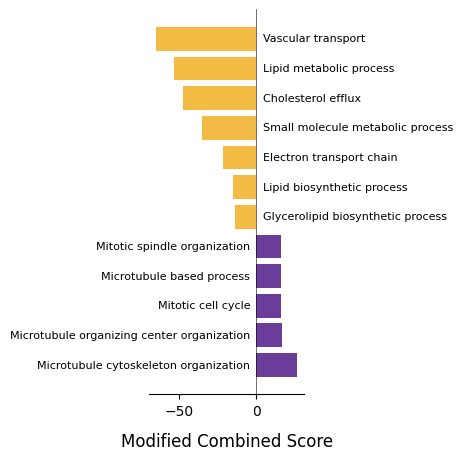

In [29]:
script_path = src_dir + 'GO_barplot.py'
%run -i $script_path
# Plot
GO_barplot(hsNcx_vs_mmDG_combined, colorbar = False, dist_neg=-4, dist_pos=4, distance=1)
# Save the plot
#fig = plt.gcf()
plt.grid(False)
plt.tight_layout()
plt.savefig(plots_dir + "GO/hs_ncx_rg2_vs_mm_dg_rg_2/Barplot_hs_ncx_rg2_vs_mm_dg_rg_2_FULL_comparison.png", dpi = 300, bbox_inches = 'tight')
plt.savefig(plots_dir + "GO/hs_ncx_rg2_vs_mm_dg_rg_2/Barplot_hs_ncx_rg2_vs_mm_dg_rg_2_FULL_comparison.svg", dpi = 300, bbox_inches = 'tight')
plt.show()